# تحلیل نتایج phi-CCT

این نوت‌بوک مخصوص کار تحلیلی و مرور نتایج است و مدل را دوباره اجرا نمی‌کند. از کد مشترک در `scripts/` و خروجی‌های کامل پروژه استفاده می‌کند. نوت‌بوک مرجع و مستقل برای تحویل، `phi_cct_esnli.ipynb` است.

۱۰۰۰ نمونهٔ ثابت، ۹۰۰۰ پاسخ واقعی و ۶۰۰۰ جفت معتبر داریم. insertion و deletion جدا تحلیل می‌شوند. نام‌موجودیت فرضیهٔ اصلی بوده؛ چهار بررسی دیگر ثانویه و از پیش مشخص‌شده‌اند.


In [1]:
from pathlib import Path
import sys,json
import pandas as pd
from IPython.display import display,Image,Markdown
ROOT=Path.cwd().parent if Path.cwd().name=="notebooks" else Path.cwd()
if not (ROOT/"config/experiment.json").exists():raise RuntimeError("Open this notebook from the supplied project folder")
sys.path.insert(0,str(ROOT/"scripts"))
CONFIG=json.loads((ROOT/"config/experiment.json").read_text())
RECOMPUTE=True  # CPU only; retains the frozen primary analysis choices


## ۱. بازتولید محاسبات و کنترل خروجی خام
تمام تطبیق labelها معنایی است. خطای تولید یا parsing نباید به صفر در E_D یا I_D تبدیل شود. بازنمونه‌گیری با واحد source_id انجام می‌شود و همهٔ editها و layoutهای یک نمونه را کنار هم نگه می‌دارد.

In [2]:
from analyze_results import analyze,VARIABLES
from review_actual_examples import run_mention_sensitivity
from verify_real_outputs import verify_real_outputs
if RECOMPUTE:
    analyze(ROOT,CONFIG,"full")
    run_mention_sensitivity(ROOT,CONFIG)
verification=verify_real_outputs(ROOT)
display(pd.DataFrame([verification]).drop(columns=["checks"]))


{
  "status": "complete",
  "mode": "full",
  "n_frozen_sources": 1000,
  "n_sources_with_valid_pairs": 1000,
  "expected_jobs": 9000,
  "completed_jobs": 9000,
  "valid_pairs": 6000,
  "sources_with_insufficient_edits": 0,
  "planned_tests": 10,
  "tests_estimable": 9,
  "bootstrap_draws": 2000,
  "bootstrap_unit": "source_id, all 1000 frozen clusters; repeated layouts and edits kept together",
  "undefined_draws": "omitted from percentile calculation; counts and unstable status exported",
  "bh_family_size": 10,
  "qualitative_review": "completed_with_analyst_review"
}
{
  "analysis": "post_hoc_nationality_attribute_mention_sensitivity",
  "primary_tests_unchanged": true,
  "rule": "For French/Canadian insertions only, count an explicit nationality/nationalities reference in the new explanation in addition to the primary lexical rule",
  "new_matches": 125,
  "new_matches_with_I1": 60,
  "proxy_audit_rows": 20,
  "scope": "only two nationality adjectives; deterministic keyword proxy,

{
  "verified_at_utc": "2026-11-16T07:48:54.387195+00:00",
  "data_type": "actual_full_run",
  "passed": true,
  "n_raw_responses": 9000,
  "n_source_examples": 1000,
  "n_pairs": 6000,
  "checks": [
    "frozen_protocol_checksums",
    "unique_jobs_and_single_configuration",
    "explanation_before_answer",
    "all_option_letters_map_to_canonical_semantics",
    "all_pair_keys_and_semantic_impacts",
    "all_edit_spans_reconstruct_text",
    "insertion_new_vs_deletion_baseline_convention",
    "phi_independent_Pearson_and_contingency_counts",
    "accuracy_independent_recalculation",
    "BH_independent_statsmodels_check"
  ],
  "checkpoint_sha256": "39aaa1e3084c32792844fa4f32ed6186c946907f8205bff6d09926c958dd1b6f"
}


,verified_at_utc,data_type,passed,n_raw_responses,n_source_examples,n_pairs,checkpoint_sha256
0,2026-11-16T07:48:54.387195+00:00,actual_full_run,True,9000,1000,6000,39aaa1e3084c32792844fa4f32ed6186c946907f8205bf...


## ۲. پوشش، دقت و معیار اصلی
دقت مربوط به label مرجع ورودی اصلی است؛ برای editها، gold جدید مستقلی تعیین نشده است. تعداد پاسخ‌ها با تعداد نمونه‌های مستقل فرق دارد.

In [3]:
coverage=pd.read_csv(ROOT/"outputs/results/coverage.csv")
display(coverage.completion_status.value_counts().to_frame("sources"))
display(pd.read_csv(ROOT/"outputs/results/accuracy.csv"))
summary=pd.read_csv(ROOT/"outputs/results/summary.csv")
display(summary[["family","n_sources","n_pairs","phi","phi_ci_low","phi_ci_high","impact_rate","mention_rate","n00","n01","n10","n11"]])


,sources
completion_status,
complete,1000


,valid_baseline_n,scheduled_baseline_n,valid_baseline_accuracy,full_coverage_correct_rate,baseline_invalid_or_missing
0,3000,3000,0.707,0.707,0


,family,n_sources,n_pairs,phi,phi_ci_low,phi_ci_high,impact_rate,mention_rate,n00,n01,n10,n11
0,insertion,1000,3240,0.194951,0.136722,0.254742,0.142901,0.209568,2285,276,492,187
1,deletion,920,2760,0.159577,0.100538,0.219386,0.162319,0.240217,1826,271,486,177


## ۳. هر پنج بررسی اجباری
فرض صفر هر آزمون برابری phi در گروه‌های آن متغیر است. آزمون omnibus از bootstrap خوشه‌ایِ مرکز‌شده استفاده می‌کند؛ این آزمون تقریبی است و اثبات علیت نیست. BH روی هر ۱۰ آزمون برنامه‌ریزی‌شده اعمال شده است. زیرگروه با کمتر از ۲۰ source مستقل طبق قاعدهٔ ازپیش‌مشخص‌شده قابل آزمون نیست.

,family,variable,p_raw,p_bh,effect_max_abs_phi_difference,status,nonestimable_reason
0,insertion,named_entity,0.000500,0.004998,0.423674,estimable,NaN
1,insertion,target_polarity,0.450275,0.561960,0.100345,estimable,NaN
2,insertion,position_bin,0.027486,0.091621,0.161384,estimable,NaN
3,insertion,idf_bin,0.010505,0.052526,0.272747,estimable,NaN
4,insertion,gold_label_option_position,0.212894,0.447276,0.046943,estimable,NaN
5,deletion,named_entity,0.505764,0.561960,0.091385,estimable,NaN
6,deletion,target_polarity,NaN,NaN,NaN,non_estimable,sparse_group_below_prespecified_source_threshold
7,deletion,position_bin,0.251874,0.447276,0.125268,estimable,NaN
8,deletion,idf_bin,0.470765,0.561960,0.083576,estimable,NaN
9,deletion,gold_label_option_position,0.268366,0.447276,0.053070,estimable,NaN


,family,variable,term,effect,ci_low,ci_high,scale
0,insertion,named_entity,non_entity minus entity,0.423674,0.288125,0.545866,phi_difference
1,insertion,target_polarity,neutral minus negative,-0.084135,-0.227893,0.065456,phi_difference
2,insertion,target_polarity,positive minus negative,-0.100345,-0.282264,0.073080,phi_difference
3,insertion,position_bin,late minus early,0.161384,0.038626,0.286650,phi_difference
4,insertion,position_bin,middle minus early,0.100855,-0.020237,0.222009,phi_difference
5,insertion,idf_bin,middle minus common,-0.186749,-0.355561,0.014646,phi_difference
6,insertion,idf_bin,rare minus common,-0.272747,-0.433043,-0.087254,phi_difference
7,insertion,gold_label_option_position,2 minus 1,0.046943,-0.015093,0.109317,phi_difference
8,insertion,gold_label_option_position,3 minus 1,-0.008301,-0.073077,0.059068,phi_difference
9,deletion,named_entity,non_entity minus entity,-0.091385,-0.357966,0.192114,phi_difference


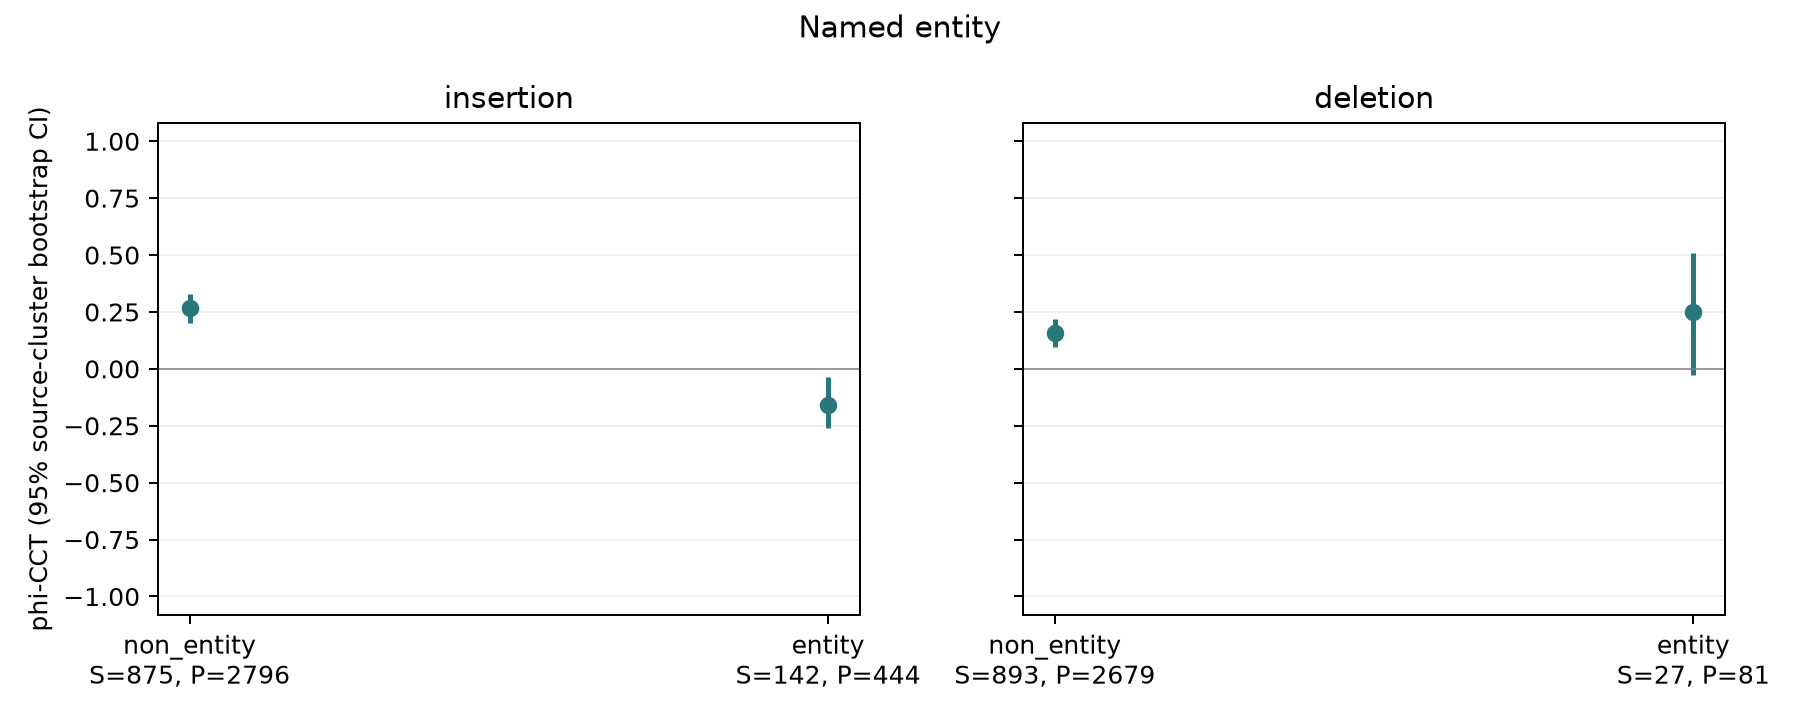

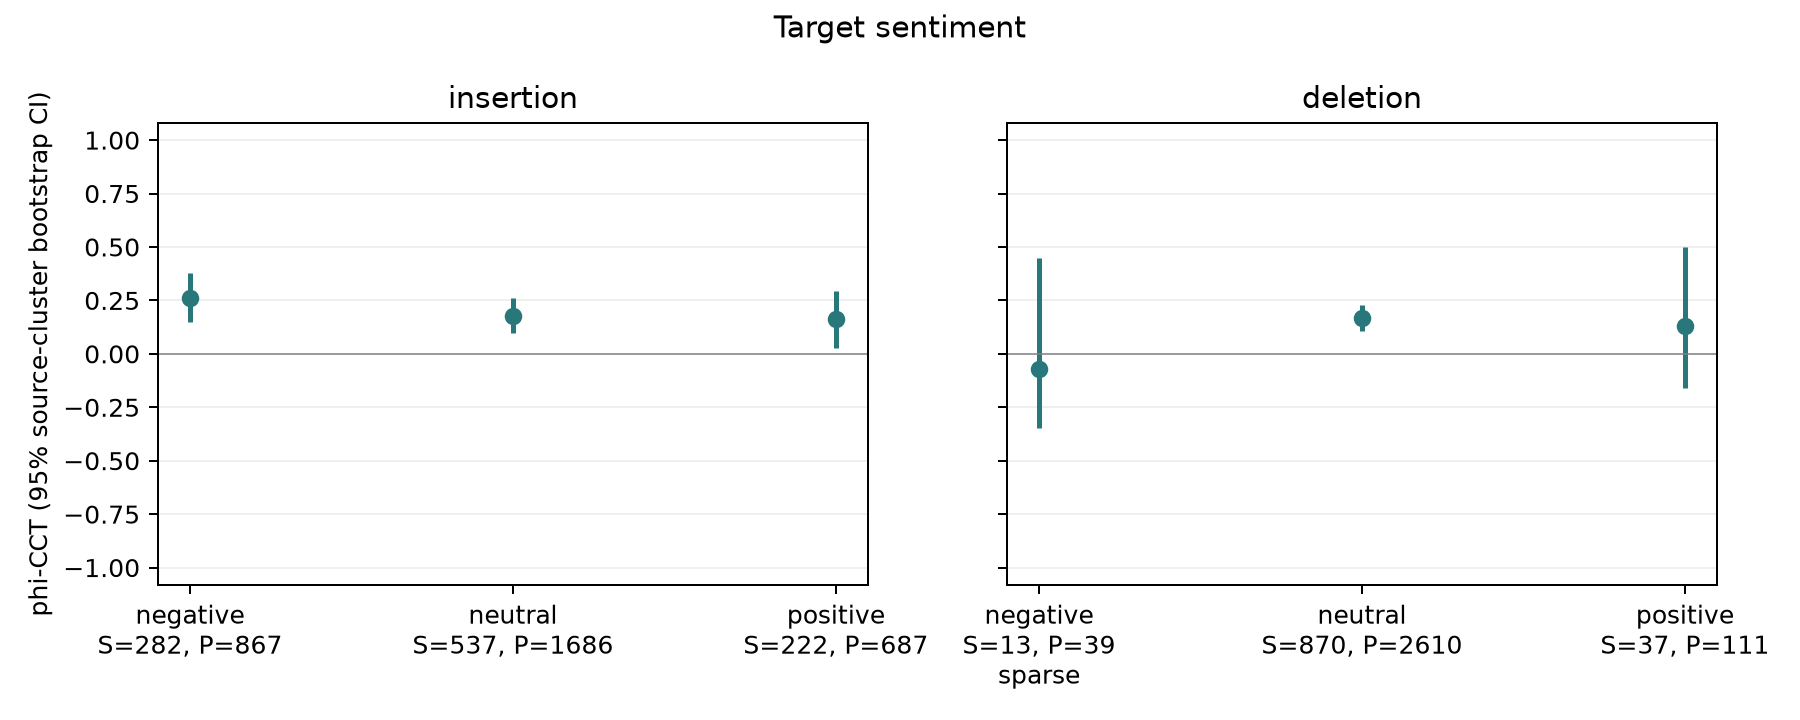

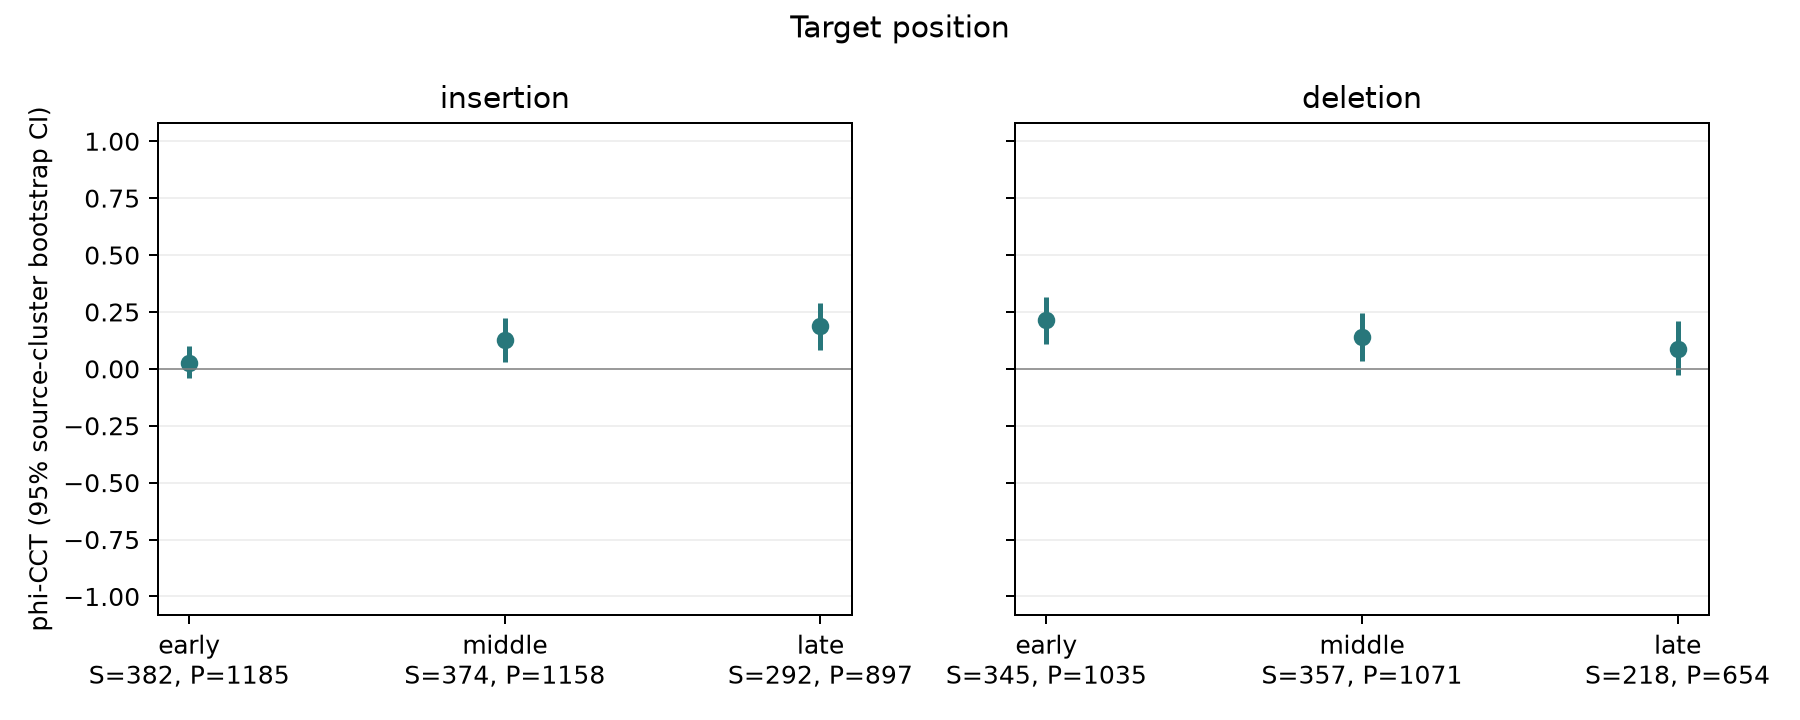

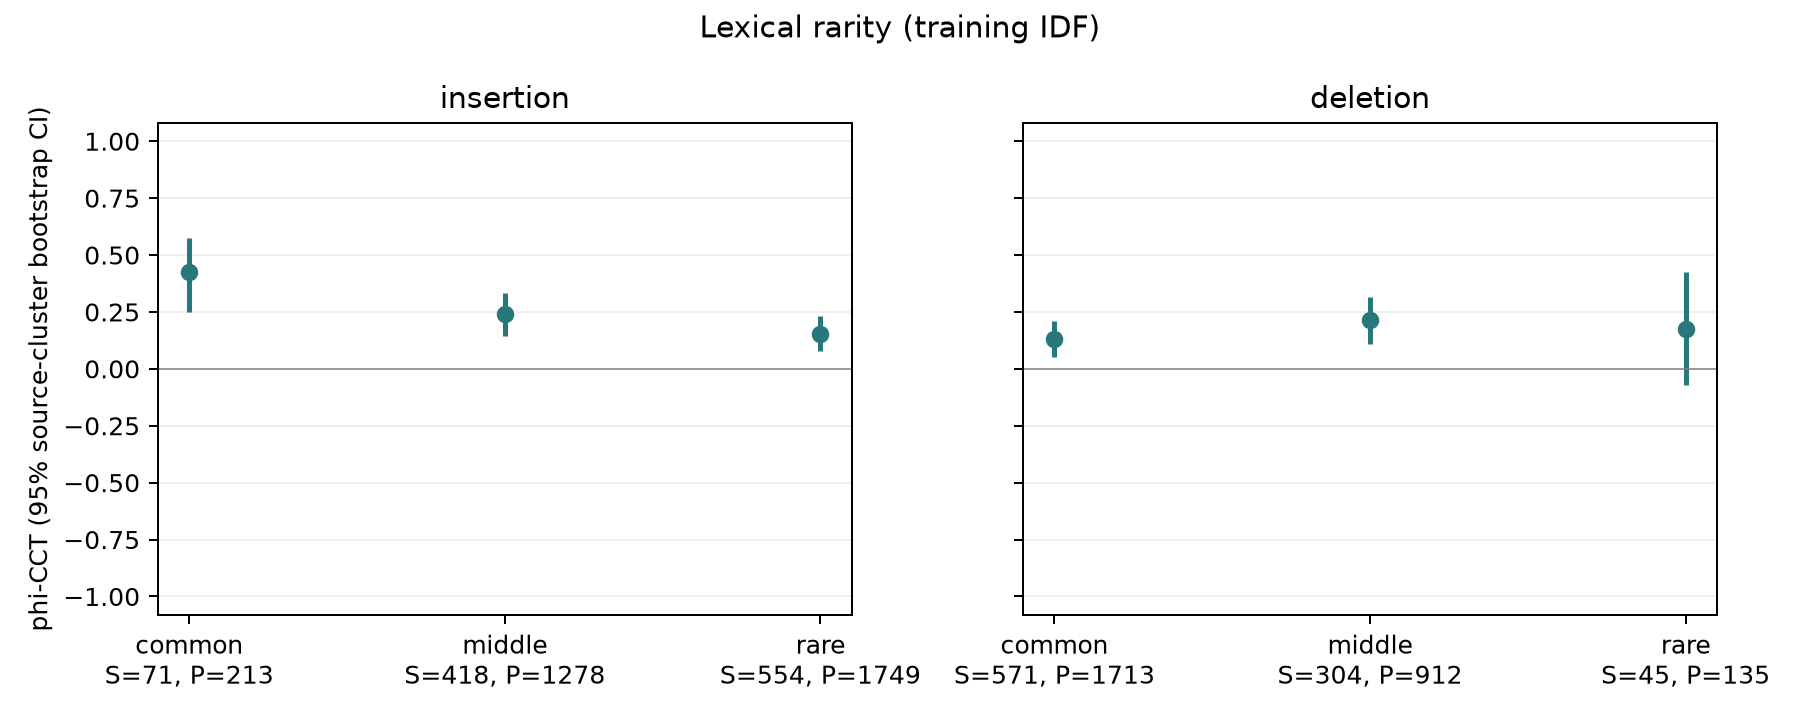

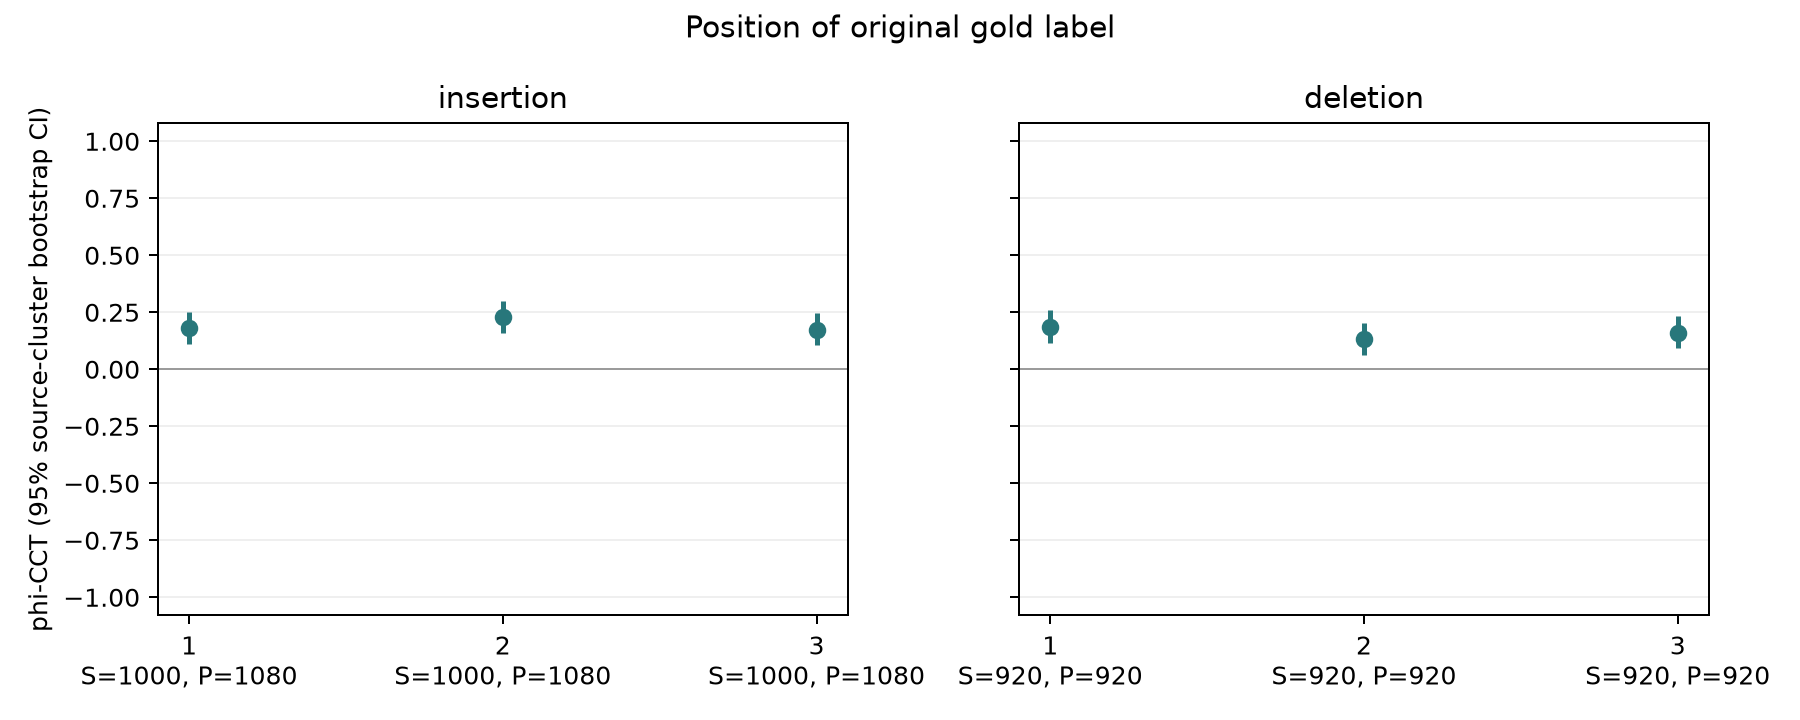

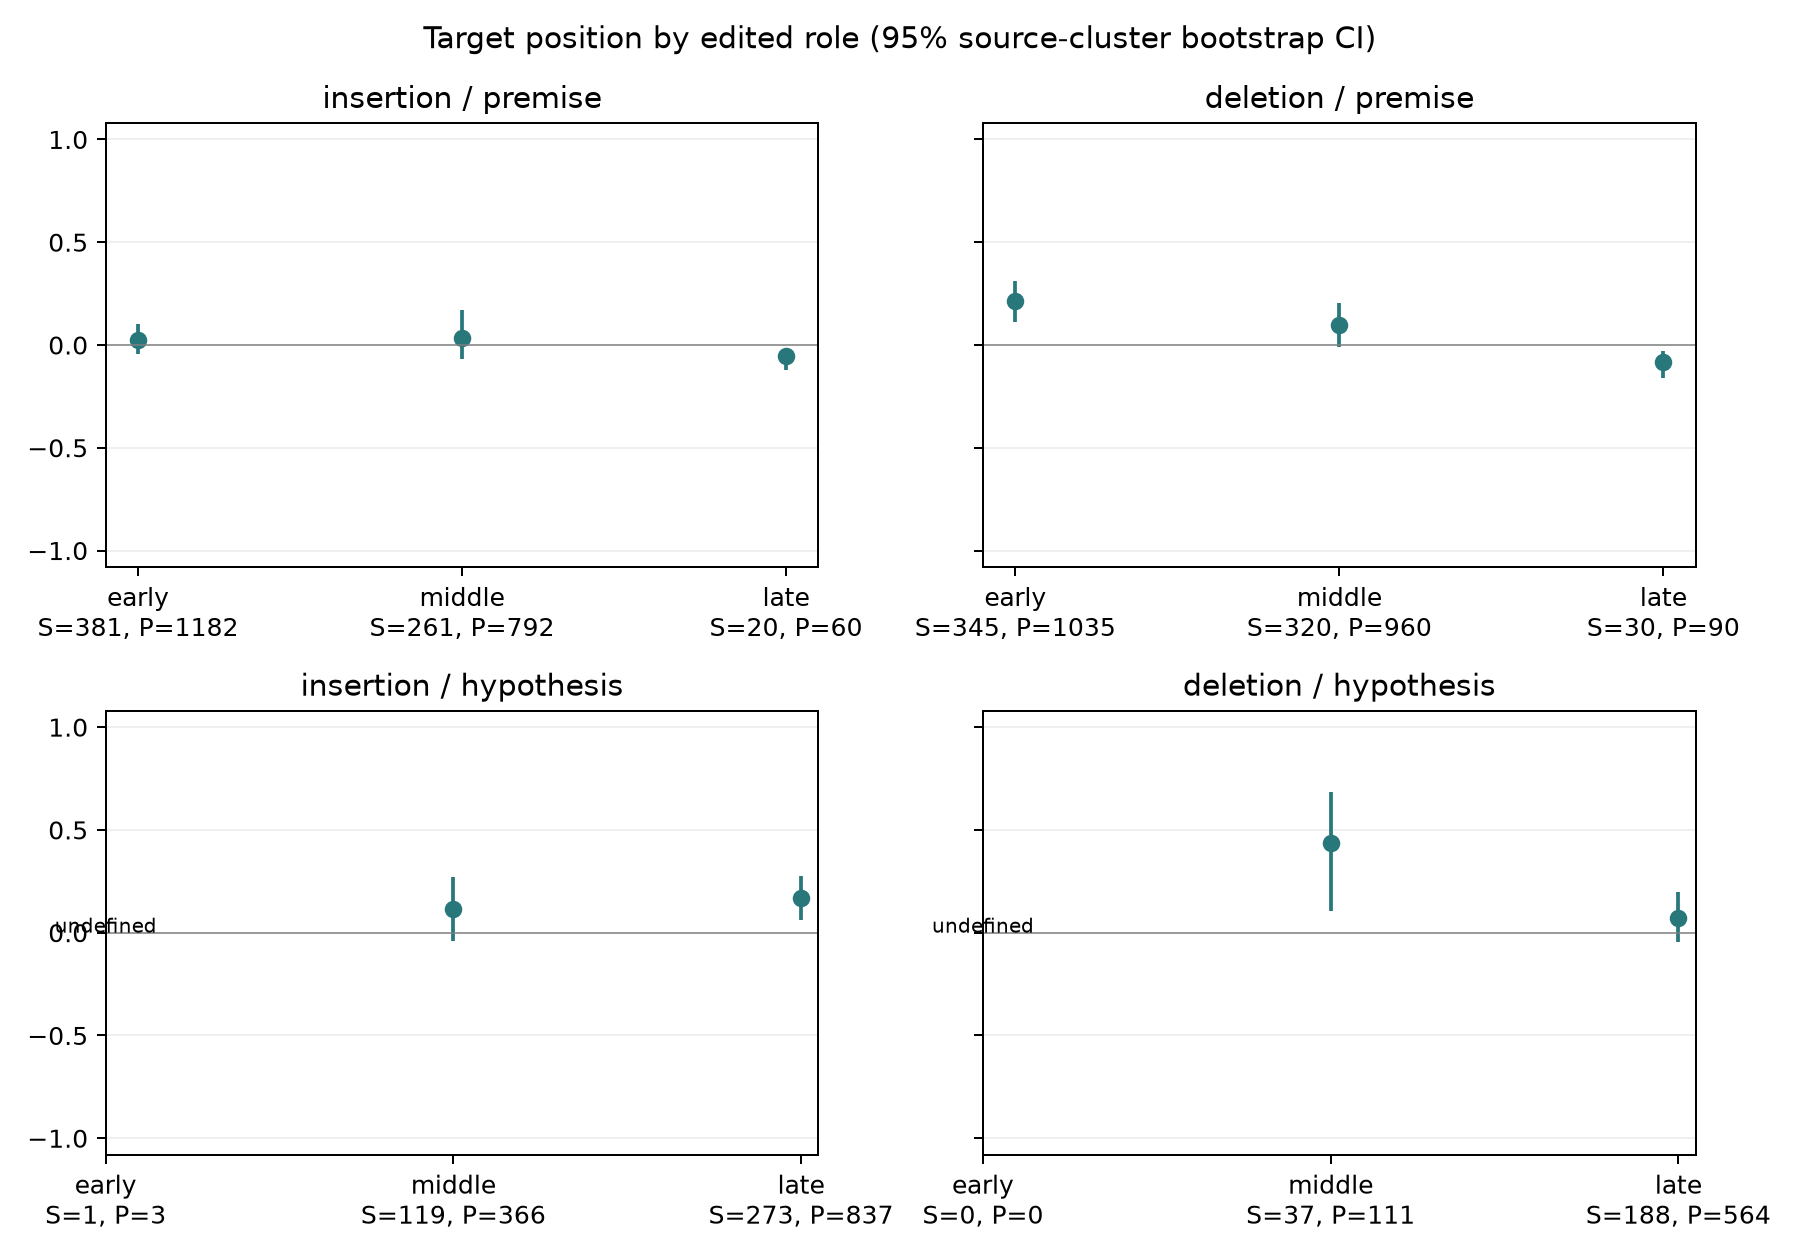

In [4]:
tests=pd.read_csv(ROOT/"outputs/results/tests.csv")
display(tests[["family","variable","p_raw","p_bh","effect_max_abs_phi_difference","status","nonestimable_reason"]])
display(pd.read_csv(ROOT/"outputs/results/phi_contrasts.csv"))
for variable in VARIABLES:display(Image(filename=str(ROOT/f"outputs/figures/{variable}.png")))
display(Image(filename=str(ROOT/"outputs/figures/position_by_role.png")))


## ۴. تفسیر اصلی
در insertion، تنها تفاوت مربوط به named entity پس از BH معنادار باقی می‌ماند: phi گروه غیرموجودیت حدود 0.265 و گروه موجودیت حدود -0.158 است. گروه موجودیت در این طراحی فقط از French و Canadian تشکیل شده؛ نتیجه به همهٔ نام‌ها یا انواع موجودیت تعمیم داده نمی‌شود. برای IDF و موقعیت، شواهد خام با نتیجهٔ پس از اصلاح چندآزمونی فرق دارد. نبود معناداری، برابری قطعی را ثابت نمی‌کند. آزمون polarity در deletion به علت ۱۳ source منفی، مطابق طرح قابل‌برآورد نیست.

## ۵. تحلیل تکمیلیِ پس از مشاهدهٔ داده: اشارهٔ معنایی به ملیت
این بخش **post-hoc** است و جایگزین نتایج اصلی نمی‌شود. در Q8 مدل می‌گوید nationality، بدون تکرار Canadian. یک proxy محدود اضافه می‌کند: برای targetهای French/Canadian، اشارهٔ صریح به nationality/nationalities هم شمرده شود. ۲۰ نمونهٔ این proxy با متن و توضیح بررسی شده‌اند؛ این ارزیابی یک مطالعهٔ مستقل انسانی یا oracle عمومی معنایی نیست.

In [5]:
display(pd.read_csv(ROOT/"outputs/results/mention_sensitivity.csv")[["level","mention_rule","n_sources","phi","phi_ci_low","phi_ci_high"]])
display(pd.read_csv(ROOT/"outputs/results/verbosity.csv"))


,level,mention_rule,n_sources,phi,phi_ci_low,phi_ci_high
0,non_entity,primary_lexical,875.0,0.265175,0.200388,0.327797
1,non_entity,nationality_attribute_proxy,875.0,0.265175,0.200388,0.327797
2,entity,primary_lexical,142.0,-0.158499,-0.260747,-0.034507
3,entity,nationality_attribute_proxy,142.0,0.256634,0.140292,0.357664
4,non_entity_minus_entity,primary_lexical,NaN,0.423674,0.288125,0.545866
5,non_entity_minus_entity,nationality_attribute_proxy,NaN,0.008540,-0.110572,0.139726


,family,n_responses,word_count_rule,requested_max_words,mean_words,median_words,max_words,over_requested_limit
0,baseline,3000,whitespace-separated words,25,20.588667,20.0,56,551
1,deletion,2760,whitespace-separated words,25,20.318841,20.0,47,454
2,insertion,3240,whitespace-separated words,25,21.465741,21.0,84,694


این proxy مقدار phi موجودیت را از حدود -0.158 به +0.257 می‌رساند؛ نزدیک به +0.265 گروه دیگر. این تغییر، حساسیت نتیجه به تعریف عملیاتیِ «اشاره» را نشان می‌دهد و سازوکار محتملی برای تفاوت اولیه فراهم می‌کند. اثر علّیِ کلی named entity یا بی‌اعتباری عمومی phi-CCT از این آزمایش اثبات نمی‌شود.

## ۶. مثال‌های کیفی قابل‌ردیابی
تفسیر Q2 شامل یک مشاهدهٔ انسانی است. سایر تفسیرها حاصل بازبینی خروجی واقعی توسط Codex هستند و یک مطالعهٔ مستقل انسانی محسوب نمی‌شوند. ردیف failure قبل از inference حذف شده و E/I برای آن تعریف نمی‌شود.

In [6]:
examples=pd.read_csv(ROOT/"outputs/qualitative/qualitative_examples.csv",keep_default_na=False)
for r in examples.to_dict("records"):
    display(Markdown(f"### {r['example_id']} — {r['case_type']}"))
    display(pd.Series({k:r.get(k,"") for k in ["source_id","edit_id","layout_id","target","original_premise","original_hypothesis","edited_premise","edited_hypothesis","baseline_explanation","edited_explanation","baseline_semantic_label","edited_semantic_label","E_D","I_D","interpretation","alternative_explanation","baseline_job_id","edited_job_id"]}).to_frame("value"))


### Q1 — rejected_intervention

,value
source_id,6757018587.jpg#0r1c
edit_id,6757018587.jpg#0r1c:deletion:008
layout_id,0
target,blue and red
original_premise,A female softball player wearing blue and red ...
original_hypothesis,the player is flying planes
edited_premise,A female softball player wearing crouches in t...
edited_hypothesis,the player is flying planes
baseline_explanation,
edited_explanation,


### Q2 — E0_I1

,value
source_id,2043520315.jpg#2r1n
edit_id,2043520315.jpg#2r1n:insertion:000
layout_id,0
target,strange
original_premise,Three hikers and a dog are walking through the...
original_hypothesis,People are hiking threw a woods.
edited_premise,Three hikers and a dog are walking through the...
edited_hypothesis,People are hiking threw a woods.
baseline_explanation,The premise describes hikers and a dog walking...
edited_explanation,The premise describes hikers and a dog on a hi...


### Q3 — E1_I0

,value
source_id,5012159302.jpg#2r1c
edit_id,5012159302.jpg#2r1c:insertion:001
layout_id,0
target,unusual
original_premise,The farmers are out working hard on there trac...
original_hypothesis,People wearing shorts are standing around doin...
edited_premise,The farmers are out working hard on there trac...
edited_hypothesis,People wearing unusual shorts are standing aro...
baseline_explanation,The premise describes farmers working on a tra...
edited_explanation,The premise describes farmers working on a tra...


... (8 outputs left out)

### Q8 — E0_I1

,value
source_id,1970275389.jpg#0r1e
edit_id,1970275389.jpg#0r1e:insertion:000
layout_id,0
target,Canadian
original_premise,A woman leans over a small fence to take a pic...
original_hypothesis,A woman is taking pictures
edited_premise,A woman leans over a small fence to take a pic...
edited_hypothesis,A Canadian woman is taking pictures
baseline_explanation,The premise describes a woman taking a picture...
edited_explanation,The premise does not specify the woman's natio...


### Q9 — E1_I0

,value
source_id,4670365996.jpg#1r1c
edit_id,4670365996.jpg#1r1c:insertion:000
layout_id,0
target,Canadian
original_premise,Woman in a blue dress and carrying a black pur...
original_hypothesis,the girl is wearing a black dress and a blue p...
edited_premise,Woman in a blue dress and carrying a black pur...
edited_hypothesis,the Canadian girl is wearing a black dress and...
baseline_explanation,The premise describes a woman in a blue dress ...
edited_explanation,The premise describes a woman in a blue dress ...


## محدودیت‌های روش‌شناختی
ویژگی‌ها و روش editها هم‌زمان تغییر می‌کنند؛ گروه ملیت فقط دو واژه دارد؛ matching واژه‌ای paraphraseها را از دست می‌دهد؛ audit دستی پیش از اجرا کلی و محدود بوده و gold جدید تعیین نشده است. محدودیت ۲۵ کلمه یک درخواست در prompt است و رعایت‌نکردنش فیلتر نشده است. گزارش اصلی دو صفحه و جزئیات کامل در CSVها و نوت‌بوک مرجع هستند. هیچ مدل یا دیتاست اختیاری به عنوان اجرای انجام‌شده گزارش نمی‌شود.